# Project 1: VaR and ES -- Estimation, Backtesting, and Model Comparison

**Names of all group members:**
- Firstname Lastname (email@example.com)
- Firstname Lastname (email@example.com)

---

## 0) Setup

Creates necessary folders, sets parameters, and fixes the random seed. Keep this seed fixed; the whole run must be reproducible from it.

In [294]:
# If a package import fails, install it in your environment, e.g.:
# %pip install arch statsmodels

import os
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path.cwd()
DATA_FILE = PROJECT_DIR / "QRM_2026_Project_prices.csv"   # provided with the project; do not re-download
OUT_DIR = PROJECT_DIR / "output"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Parameters
TICKERS = ["AAPL", "META", "JPM"]   # every question is run separately on each stock
WINDOW = 504                        # estimation window of every model, in trading days (Questions 2-5)
EVAL_START = 504                    # Questions 3-5: forecast days are all days after the first 504
REFIT = 21                          # Questions 4-5: re-estimate every this many trading days
ALPHAS = [0.975, 0.99]              # confidence levels used throughout Questions 2-5
DEEP_ALPHA = 0.999                  # Question 6: the extreme level EVT is asked for
M_SIM = 10_000                      # Questions 3(c), 4(d): Acerbi-Szekely simulated samples
LB_LAGS = 10                        # Ljung-Box H in Questions 1 and 4
NW_LAGS = 10                        # Newey-West truncation lag of the Diebold-Mariano test
SEED = 0                            # fix this, state it in the report, do not change it later

rng = np.random.default_rng(SEED)
print("Project dir:", PROJECT_DIR)


Project dir: C:\Users\Marco Saitta\Documents\AAA_EPFL_S3\QRM\QRM_project


## 1) Data

The prices were downloaded once with `yfinance` (adjusted closes, 2 January 2013 to 30 June 2026,
downloaded on 28 October 2026) and are provided as `QRM_2026_Project_prices.csv`. Read this file;
do not download the data again, since Yahoo revises adjusted prices back in time.

In [295]:
price_df = pd.read_csv(DATA_FILE, index_col=0, parse_dates=True)[TICKERS]
print(price_df.shape, price_df.index[0].date(), "to", price_df.index[-1].date())   # (3393, 3)

(3393, 3) 2013-01-02 to 2026-06-30


In [296]:
price_df

,AAPL,META,JPM
Date,,,
2013-01-02,16.5671,27.7344,31.0455
2013-01-03,16.3580,27.5065,30.9829
2013-01-04,15.9024,28.4872,31.5321
2013-01-07,15.8088,29.1409,31.5668
2013-01-08,15.8514,28.7843,31.6294
...,...,...,...
2026-06-24,292.8274,557.2302,330.3067
2026-06-25,274.9129,542.4419,331.9609
2026-06-26,283.5355,549.8161,325.9482


## 2) Log-returns and losses

Construct $R_t=\log(P_t/P_{t-1})$ for each ticker. The log-loss used everywhere in this project is
$L_t=-R_t$. Every question is run separately on each of the three columns; there is no portfolio.

In [297]:
returns = np.log(price_df / price_df.shift(1)).dropna()
losses = -returns

print(returns.shape, returns.index[0].date(), "to", returns.index[-1].date())   # (3392, 3)
returns.head()

(3392, 3) 2013-01-03 to 2026-06-30


,AAPL,META,JPM
Date,,,
2013-01-03,-0.0127,-0.0082,-0.0020
2013-01-04,-0.0282,0.0350,0.0176
2013-01-07,-0.0059,0.0227,0.0011
2013-01-08,0.0027,-0.0123,0.0020
2013-01-09,-0.0158,0.0513,-0.0007


## Question 1 -- Stylized facts

For each stock: (a) plot the return series; (b) ACF of returns and of squared returns, and the
Ljung-Box test with $H$ = `LB_LAGS` on both (`statsmodels.stats.diagnostic.acorr_ljungbox`);
(c) QQ-plot and Jarque-Bera.

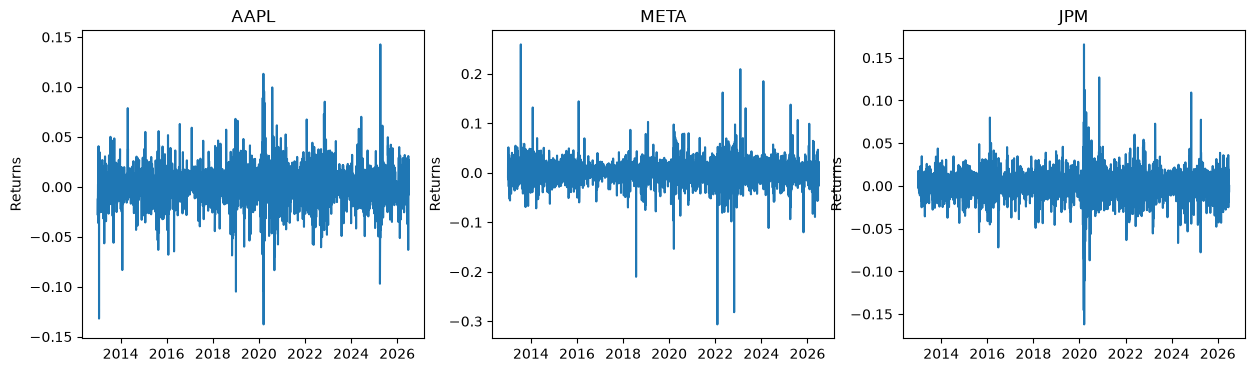

In [298]:
# Question 1

plt.figure(figsize=(15,4))

plt.subplot(1,3,1)
plt.plot(returns["AAPL"])
plt.ylabel("Returns")
plt.title("AAPL")

plt.subplot(1,3,2)
plt.plot(returns["META"])
plt.ylabel("Returns")
plt.title("META")

plt.subplot(1,3,3)
plt.plot(returns["JPM"])
plt.ylabel("Returns")
plt.title("JPM")

plt.show()

Text(0, 0.5, 'ACF')

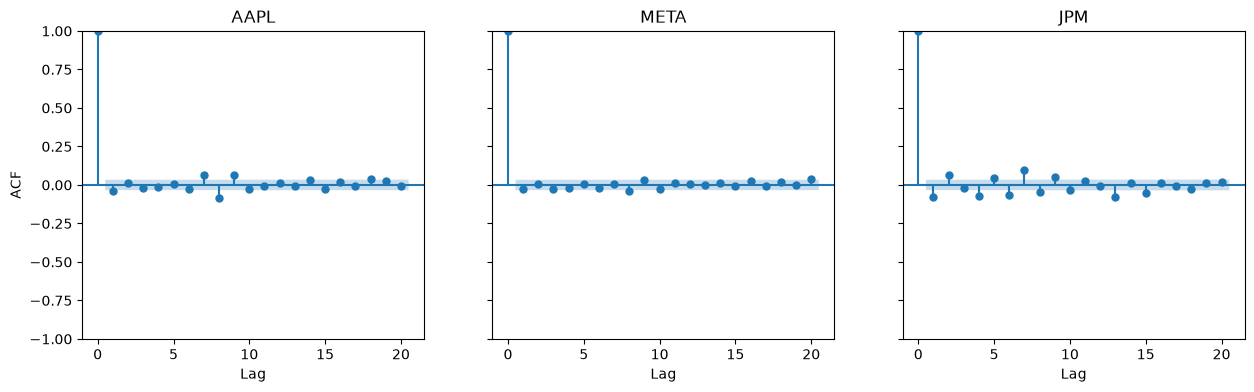

In [299]:
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import acf

acf_AAPL = acf(returns["AAPL"].dropna(), nlags=20)
acf_META = acf(returns["META"].dropna(), nlags=20)
acf_JPM = acf(returns["JPM"].dropna(), nlags=20)


fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

tickers = ["AAPL", "META", "JPM"]
for ax, ticker in zip(axes, tickers):
    plot_acf(returns[ticker].dropna(), lags=20, alpha=0.05, ax=ax)
    ax.set_title(ticker)
    ax.set_xlabel("Lag")


axes[0].set_ylabel("ACF")


Text(0, 0.5, 'ACF')

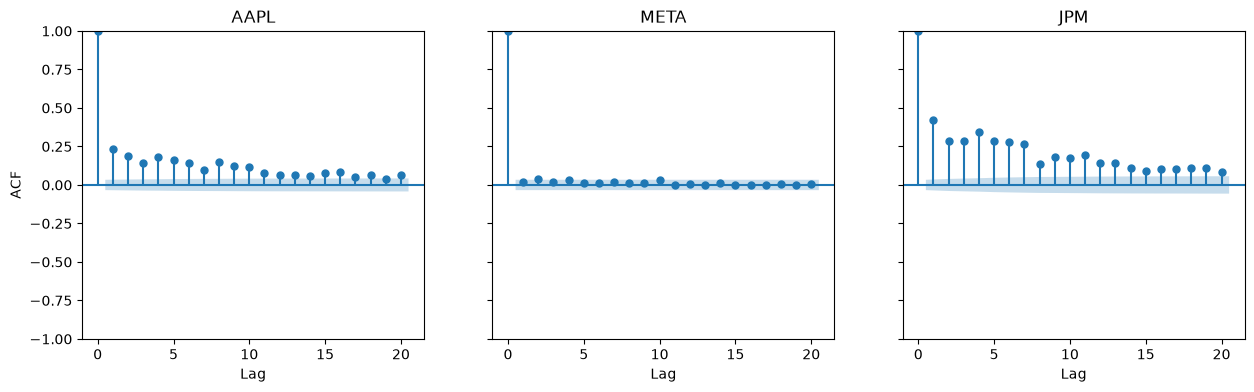

In [300]:
acf_AAPL2 = acf((returns["AAPL"].dropna())**2, nlags=20)
acf_META2 = acf((returns["META"].dropna())**2, nlags=20)
acf_JPM2 = acf((returns["JPM"].dropna())**2, nlags=20)


fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

tickers = ["AAPL", "META", "JPM"]
for ax, ticker in zip(axes, tickers):
    plot_acf((returns[ticker]**2).dropna(), lags=20, alpha=0.05, ax=ax)
    ax.set_title(ticker)
    ax.set_xlabel("Lag")


axes[0].set_ylabel("ACF")


In [301]:
from statsmodels.stats.diagnostic import acorr_ljungbox

results_lb = []
for ticker in tickers:
    lb_returns = acorr_ljungbox(returns[ticker], lags=[LB_LAGS], return_df=True)
    lb_squared = acorr_ljungbox(returns[ticker]**2, lags=[LB_LAGS], return_df=True)

    results_lb.append({"Ticker": ticker,"p_returns": lb_returns["lb_pvalue"].iloc[0],"p_squared": lb_squared["lb_pvalue"].iloc[0]})

results_lb = pd.DataFrame(results_lb)
print(results_lb)

  Ticker  p_returns  p_squared
0   AAPL     0.0000     0.0000
1   META     0.0335     0.0390
2    JPM     0.0000     0.0000


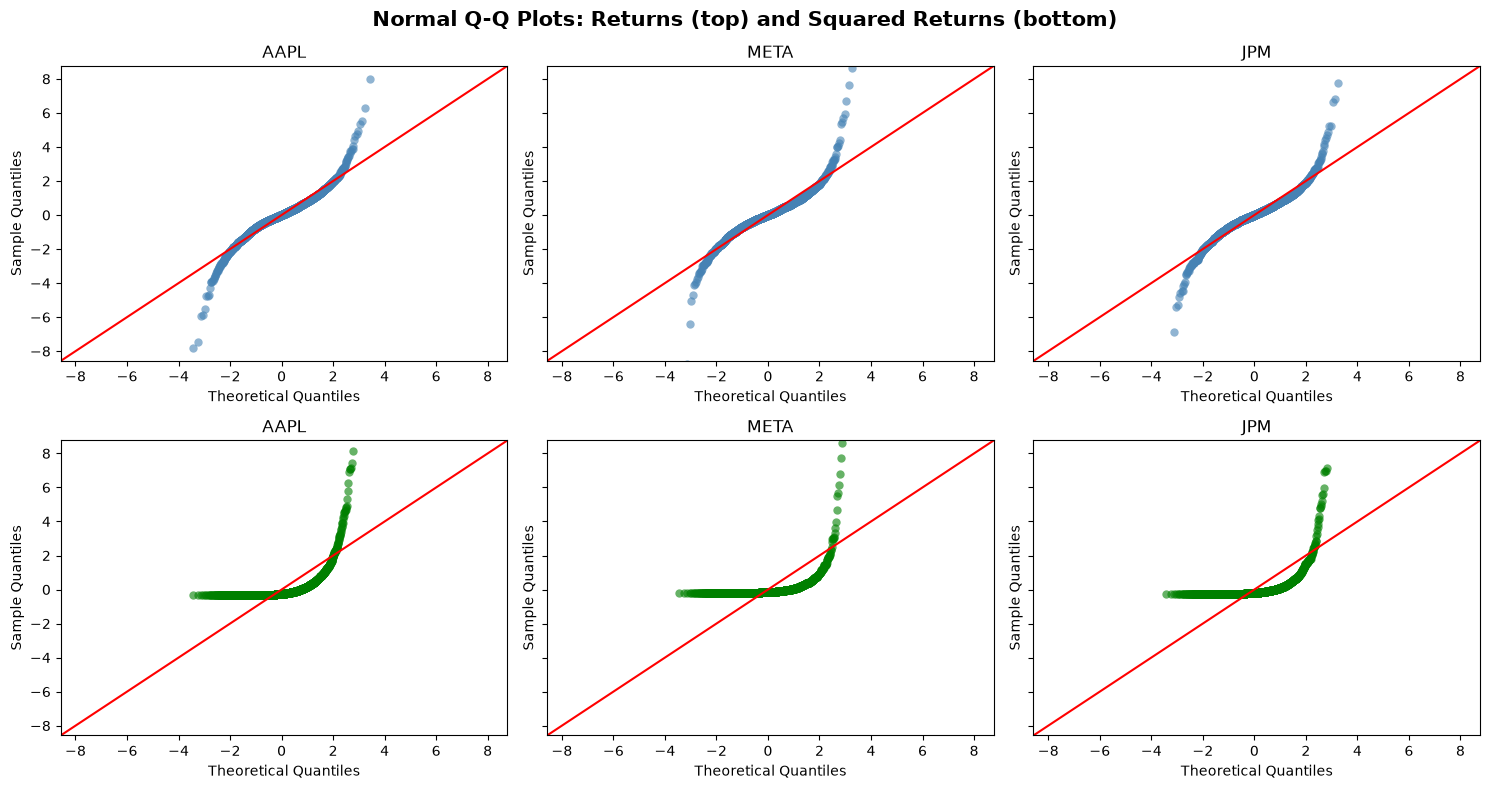

In [302]:
import statsmodels.api as sm


fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey=True)

for i, ticker in enumerate(tickers):
    sm.qqplot(returns[ticker], fit=True, line="45", ax=axes[0,i], markerfacecolor="steelblue", markeredgecolor="none",alpha=0.6)
    sm.qqplot(returns[ticker]**2, fit=True, line="45", ax=axes[1,i], markerfacecolor="green", markeredgecolor="none",alpha=0.6)

    axes[0, i].set_title(ticker)
    axes[1, i].set_title(ticker)

fig.suptitle("Normal Q-Q Plots: Returns (top) and Squared Returns (bottom)", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

In [303]:
from scipy.stats import jarque_bera

jb_values = []

for ticker in tickers: 
    stat, pvalue = jarque_bera(returns[ticker].dropna())
    jb_values.append({"Ticker": ticker,"stat": stat,"pvalue": pvalue})

jb_values = pd.DataFrame(jb_values)
print(jb_values)

  Ticker       stat  pvalue
0   AAPL  6590.6140  0.0000
1   META 84216.0510  0.0000
2    JPM 23655.8191  0.0000


## Question 2 -- Single-window VaR and ES estimates

For each stock, use the first `WINDOW` losses as the single estimation window for (a)-(d).

In [304]:
# Question 2
window_loss = losses.iloc[:WINDOW]          # one column per stock

In [305]:
# Historical 

VaR_ES_hist = []

for ticker in tickers:
    VaR = []
    ES = []
    losses = window_loss[ticker].dropna().sort_values(ascending=False)

    for alpha in ALPHAS:
        n_tail = len(losses) * (1 - alpha)
        k = int(n_tail)
        excess = n_tail - k

        VaR_alpha = losses.iloc[k]
        ES_alpha = (losses.iloc[:k].sum() + losses.iloc[k] * excess) / n_tail

        VaR.append(VaR_alpha)
        ES.append(ES_alpha)

    VaR_ES_hist.append({"Ticker": ticker, "VaR_975": VaR[0], "ES_975": ES[0],
                        "VaR_99": VaR[1], "ES_99": ES[1]})

VaR_ES_hist = pd.DataFrame(VaR_ES_hist)
print(VaR_ES_hist.to_string(index=False, float_format="%.4f"))


Ticker  VaR_975  ES_975  VaR_99  ES_99
  AAPL   0.0290  0.0497  0.0389 0.0739
  META   0.0423  0.0560  0.0535 0.0653
   JPM   0.0238  0.0292  0.0278 0.0354


In [306]:
# Gaussian

from scipy.stats import norm

VaR_ES_gauss = []

for ticker in tickers:
    VaR = []
    ES = []
    mean, std = window_loss[ticker].mean(), window_loss[ticker].std()

    for alpha in ALPHAS:
        z = norm.ppf(alpha)

        VaR_alpha = mean + z * std
        ES_alpha = mean + std * norm.pdf(z) / (1 - alpha)

        VaR.append(VaR_alpha)
        ES.append(ES_alpha)

    VaR_ES_gauss.append({"Ticker": ticker, "VaR_975": VaR[0], "ES_975": ES[0],
                         "VaR_99": VaR[1], "ES_99": ES[1]})

VaR_ES_gauss = pd.DataFrame(VaR_ES_gauss)
print(VaR_ES_gauss)


  Ticker  VaR_975  ES_975  VaR_99  ES_99
0   AAPL   0.0307  0.0367  0.0365 0.0420
1   META   0.0472  0.0567  0.0564 0.0649
2    JPM   0.0220  0.0264  0.0262 0.0302


In [307]:
# Student-t
from scipy.stats import t

VaR_ES_stu = []

for ticker in tickers:
    VaR = []
    ES = []
    nu, mu, sigma = t.fit(window_loss[ticker].dropna())

    for alpha in ALPHAS:
        q = t.ppf(alpha, df=nu)

        VaR_alpha = mu + sigma * q
        ES_alpha = mu + sigma * ((nu + q**2) / (nu - 1)) * t.pdf(q, df=nu) / (1 - alpha)

        VaR.append(VaR_alpha)
        ES.append(ES_alpha)

    VaR_ES_stu.append({"Ticker": ticker, "nu": nu, "VaR_975": VaR[0], "ES_975": ES[0],
                       "VaR_99": VaR[1], "ES_99": ES[1]})

VaR_ES_stu = pd.DataFrame(VaR_ES_stu)
print(VaR_ES_stu)


  Ticker     nu  VaR_975  ES_975  VaR_99  ES_99
0   AAPL 4.1324   0.0295  0.0425  0.0399 0.0556
1   META 4.6793   0.0454  0.0635  0.0603 0.0814
2    JPM 6.4827   0.0224  0.0299  0.0289 0.0369


In [310]:
print(VaR_ES_gauss.columns.tolist())
print(VaR_ES_stu.columns.tolist())

['Ticker', 'VaR_975', 'ES_975', 'VaR_99', 'ES_99']
['Ticker', 'nu', 'VaR_975', 'ES_975', 'VaR_99', 'ES_99']


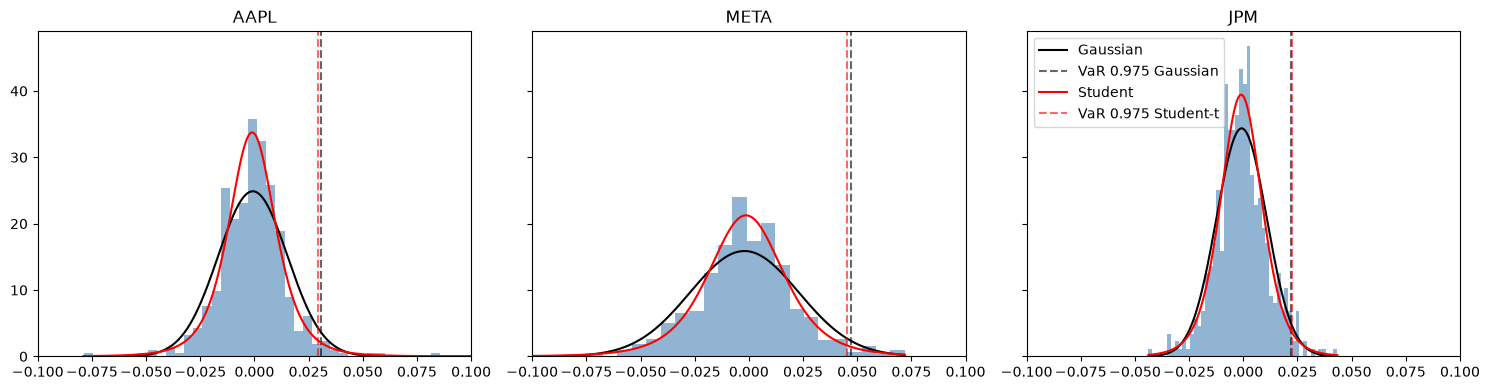

In [311]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

tickers = ["AAPL", "META", "JPM"]

for ax, ticker in zip(axes, tickers):
    mean, std = window_loss[ticker].mean(), window_loss[ticker].std()
    nu, mu, sigma = t.fit(window_loss[ticker])

    x = np.linspace(window_loss[ticker].min(), window_loss[ticker].max(), 500)

    ax.plot(x, norm.pdf(x, loc=mean, scale=std), color="black", label="Gaussian")
    ax.axvline(VaR_ES_gauss.loc[VaR_ES_gauss["Ticker"] == ticker, "VaR_975"].iloc[0], color="black", linestyle="--", alpha=0.6, label="VaR 0.975 Gaussian")

    ax.plot(x, t.pdf(x, df=nu, loc=mu, scale=sigma), color="red", label="Student")
    ax.axvline(VaR_ES_stu.loc[VaR_ES_stu["Ticker"] == ticker, "VaR_975"].iloc[0], color="red", linestyle="--", alpha=0.6, label="VaR 0.975 Student-t")

    ax.hist(window_loss[ticker], bins=50, density=True, color="steelblue", alpha=0.6)
    ax.set_xlim([-0.10, 0.10])
    ax.set_title(ticker)

axes[-1].legend()
plt.tight_layout()
plt.show()


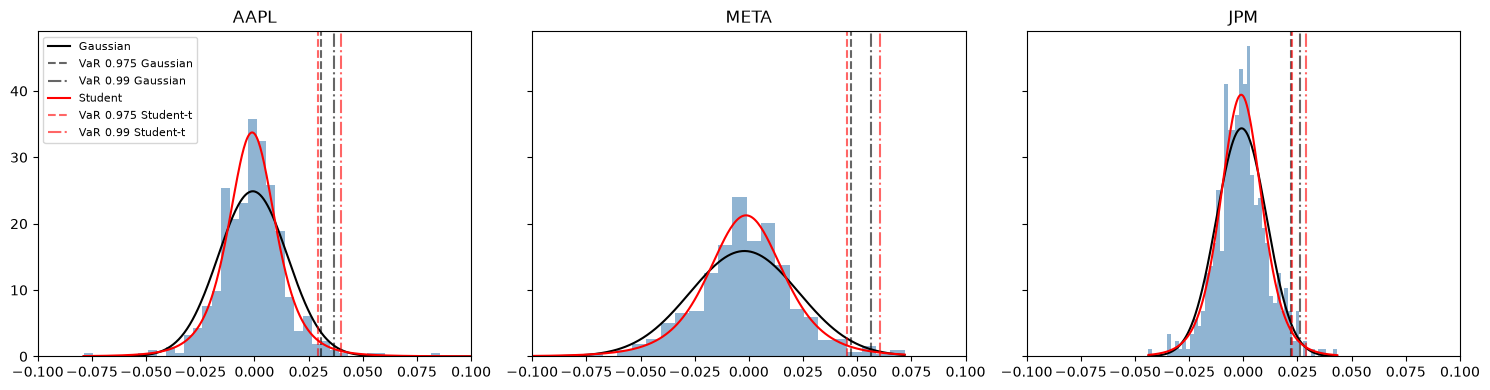

In [309]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

tickers = ["AAPL", "META", "JPM"]
for ax, ticker in zip(axes, tickers):
    mean, std = window_loss[ticker].mean(), window_loss[ticker].std()
    nu, mu, sigma = t.fit(window_loss[ticker])

    x = np.linspace(window_loss[ticker].min(), window_loss[ticker].max(), 500)

    ax.plot(x, norm.pdf(x, loc=mean, scale=std), color="black", label="Gaussian")
    ax.axvline(VaR_ES_gauss.loc[VaR_ES_gauss["Ticker"] == ticker, "VaR_975"].iloc[0],
               color="black", linestyle="--", alpha=0.6, label="VaR 0.975 Gaussian")
    ax.axvline(VaR_ES_gauss.loc[VaR_ES_gauss["Ticker"] == ticker, "VaR_99"].iloc[0],
               color="black", linestyle="-.", alpha=0.6, label="VaR 0.99 Gaussian")

    ax.plot(x, t.pdf(x, df=nu, loc=mu, scale=sigma), color="red", label="Student")
    ax.axvline(VaR_ES_stu.loc[VaR_ES_stu["Ticker"] == ticker, "VaR_975"].iloc[0],
               color="red", linestyle="--", alpha=0.6, label="VaR 0.975 Student-t")
    ax.axvline(VaR_ES_stu.loc[VaR_ES_stu["Ticker"] == ticker, "VaR_99"].iloc[0],
               color="red", linestyle="-.", alpha=0.6, label="VaR 0.99 Student-t")

    ax.hist(window_loss[ticker], bins=50, density=True, color="steelblue", alpha=0.6)
    ax.set_xlim([-0.10, 0.10])
    ax.set_title(ticker)
    if ticker == "AAPL":
        ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

## Question 3 -- Backtesting

Forecast every day of the evaluation period `losses.iloc[EVAL_START:]`, each model estimated on the
`WINDOW` days before the forecast day. Historical simulation, Gaussian and Student-$t$ are recomputed
every day. Write the Kupiec, Christoffersen, Acerbi-Szekely, Fissler-Ziegel, pinball-loss and
Diebold-Mariano functions yourself, from the course slides (Kupiec, Christoffersen) and Appendix A of
the project statement (the others); they are
reused unchanged in Questions 4 and 5.

The combined VaR backtest table collects the VaR backtests of Questions 3-5: append one row per
stock, method and level to `backtest_rows` as you go. The ES backtest table ($\alpha=0.975$) collects
the Acerbi-Szekely and Fissler-Ziegel results of Questions 3 and 4 in `es_rows`.

In [312]:
# Question 3
eval_loss = losses.iloc[EVAL_START:]        # one column per stock, 2888 forecast days
backtest_rows = []                          # dicts: stock, method, alpha, x, expected, hit, p_uc, p_ind, p_cc, pinball_bp
es_rows = []                                # dicts: stock, method, Z, p_Z, FZ


## Question 4 -- AR-GARCH conditional VaR and ES

(a) Mean model, full sample: fit AR($p$), $p=0,\dots,3$, with constant variance on the same
observations, e.g. `ARX(y, lags=p, hold_back=3)` from `arch.univariate`; pick $p$ by BIC (also report
AIC); Ljung-Box on the residuals (`model_df=p`) and on their squares.
(b) Fit `arch_model(y, mean="AR", lags=p, vol="GARCH", p=1, q=1, dist=..., hold_back=3)` on the full
sample with `dist="normal"` and `dist="t"` (use `mean="Constant"` if $p=0$); Ljung-Box on the
standardized residuals of the Gaussian fit (`model_df=p`) and their squares (`model_df=2`).
(c) Re-estimate both inside the rolling scheme every `REFIT` days with the same $p$. Between refits,
keep the parameters fixed but advance $\hat\mu_t$ and $\hat\sigma_t$ daily with the realized
returns (for example with `arch_model(...).fix(params)` on the data up to the forecast day). Fit on
returns in percent (`100 * R`) to avoid `arch` convergence warnings, and convert the forecasts back.
(d) Backtest both and add them to the two tables.

In [313]:
REFIT = 21                          # Questions 4-5: re-estimate every this many trading days
ALPHAS = [0.975, 0.99]              # confidence levels used throughout Questions 2-5
M_SIM = 10_000                      # Questions 3(c), 4(d): Acerbi-Szekely simulated samples


In [314]:
# Question 4
from arch.univariate import ARX

fits_tickers = []
residuals = {}

for ticker in tickers:
    fits = []
    for p in [0, 1, 2, 3]:
        fit = ARX(100*returns[ticker], lags=p, hold_back=3).fit(disp="off")
        fits_tickers.append({"ticker": ticker, "p": p, "BIC": fit.bic, "AIC": fit.aic, "coefficients": fit.params.to_dict()})
        residuals[(ticker, p)] = fit.resid

fits_tickers = pd.DataFrame(fits_tickers)
print(fits_tickers[["ticker", "p", "BIC", "AIC"]].round(2).to_string(index=False))

p_bic_aic = []
for ticker in tickers:
    df = fits_tickers[fits_tickers["ticker"] == ticker]
    m_bic = df["BIC"].min()
    m_aic = df["AIC"].min()
    p_bic = df[df["BIC"] == m_bic]["p"].iloc[0]
    p_aic = df[df["AIC"] == m_aic]["p"].iloc[0]
    p_bic_aic.append({"ticker":ticker , "best_p_bic":p_bic, "best_p_aic":p_aic})

p_bic_aic = pd.DataFrame(p_bic_aic)
p_bic_aic

ticker  p        BIC        AIC
  AAPL  0 13536.9300 13524.6700
  AAPL  1 13539.0100 13520.6200
  AAPL  2 13546.7800 13522.2700
  AAPL  3 13553.5200 13522.8800
  META  0 15591.5600 15579.3000
  META  1 15597.0700 15578.6900
  META  2 15605.1800 15580.6700
  META  3 15610.9700 15580.3300
   JPM  0 12953.0700 12940.8100
   JPM  1 12941.0400 12922.6500
   JPM  2 12937.9700 12913.4600
   JPM  3 12945.6700 12915.0300


,ticker,best_p_bic,best_p_aic
0,AAPL,0,1
1,META,0,1
2,JPM,2,2


In [315]:
residuals_best_p = []

for ticker in tickers:
    p = int(p_bic_aic[p_bic_aic["ticker"] == ticker]["best_p_bic"].iloc[0])
    fit = ARX(100*returns[ticker], lags=p if p > 0 else None, hold_back=3).fit(disp="off")
    residuals_best_p.append(fit.resid)

residuals_best_p = pd.concat(residuals_best_p, axis=1)
residuals_best_p.columns = tickers

residuals_best_p;

In [316]:
p_bic_aic
p_bic = p_bic_aic["best_p_bic"]
p_bic

0    0
1    0
2    2
Name: best_p_bic, dtype: int64

In [317]:
from statsmodels.stats.diagnostic import acorr_ljungbox

lb_lb2 = []

for ticker in tickers:
    p = int(p_bic_aic[p_bic_aic["ticker"] == ticker]["best_p_bic"].iloc[0])
    resid = residuals_best_p[ticker].dropna()

    lb = acorr_ljungbox(resid, lags=[10], model_df=p, return_df=True)
    lb2 = acorr_ljungbox(resid**2, lags=[10], model_df=p, return_df=True)
    print(ticker)
    print("Residuals:"), display(lb)
    print("Squared residuals:"), display(lb2)

AAPL
Residuals:


,lb_stat,lb_pvalue
10,64.2282,0.0000


Squared residuals:


,lb_stat,lb_pvalue
10,861.0194,0.0000


META
Residuals:


,lb_stat,lb_pvalue
10,19.8079,0.0311


... (2 outputs left out)

JPM
Residuals:


,lb_stat,lb_pvalue
10,64.4515,0.0000


Squared residuals:


,lb_stat,lb_pvalue
10,2300.4162,0.0000


Pour les trois actions, les p-values des résidus au carré sont inférieures à 0,05. On rejette donc l'hypothèse d'absence d'autocorrélation des résidus au carré jusqu'au lag 10. statistique de 861,0 : Cela suggère que les erreurs présentent une forte dépendance dans leur amplitude : les périodes de forte volatilité ont tendance à se regrouper.

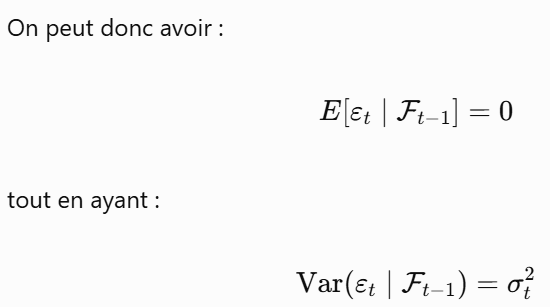



In [318]:
# b
from arch import arch_model

fits_garch_gauss = []
fits_garch_stu = []
lb_lb2_gauss = []

for ticker, p in zip(tickers,p_bic):
    mean = "AR" if p > 0 else "Constant"
    lag = p if p>0 else None
    fit_garch_gauss = arch_model(100*returns[ticker], mean=mean, lags=lag, vol="GARCH", p=1, q=1, dist="normal", hold_back=3).fit(disp="off")
    fit_garch_stu = arch_model(100*returns[ticker], mean=mean, lags=lag, vol="GARCH", p=1, q=1, dist="t", hold_back=3).fit(disp="off")

    fits_garch_gauss.append({"ticker": ticker, "p": p, "BIC": fit_garch_gauss.bic, "AIC": fit_garch_gauss.aic, "coefficients": fit_garch_gauss.params.to_dict()})
    fits_garch_stu.append({"ticker": ticker, "p": p, "BIC": fit_garch_stu.bic, "AIC": fit_garch_stu.aic, "coefficients": fit_garch_stu.params.to_dict()})

    resid_g = fit_garch_gauss.std_resid.dropna()


    lb = acorr_ljungbox(resid_g, lags=[10], model_df=p, return_df=True)
    lb2 = acorr_ljungbox(resid_g**2, lags=[10], model_df=2, return_df=True)
    lb_lb2_gauss.append({"ticker": ticker, "LB stat": lb["lb_stat"].iloc[0], "LB p-value": lb["lb_pvalue"].iloc[0], "LB² stat": lb2["lb_stat"].iloc[0], "LB² p-value": lb2["lb_pvalue"].iloc[0]})
    
fits_garch_gauss = pd.DataFrame(fits_garch_gauss)
fits_garch_stu = pd.DataFrame(fits_garch_stu)
lb_lb2_gauss = pd.DataFrame(lb_lb2_gauss)

print(fits_garch_gauss[["ticker", "p", "BIC", "AIC"]].round(2).to_string(index=False))
print(fits_garch_stu[["ticker", "p", "BIC", "AIC"]].round(2).to_string(index=False))
display(lb_lb2_gauss.round(4))


ar_best = fits_tickers.loc[fits_tickers.groupby("ticker")["BIC"].idxmin()].copy()

ticker  p        BIC        AIC
  AAPL  0 12958.5300 12934.0100
  META  0 15330.7800 15306.2700
   JPM  2 12058.3800 12021.6100
ticker  p        BIC        AIC
  AAPL  0 12596.0500 12565.4100
  META  0 14210.1700 14179.5300
   JPM  2 11736.3900 11693.5000


,ticker,LB stat,LB p-value,LB² stat,LB² p-value
0,AAPL,15.2969,0.1216,3.9561,0.8611
1,META,10.2601,0.4180,1.3192,0.9953
2,JPM,6.0062,0.6465,4.8374,0.7748


After fitting the AR-GARCH model, the Ljung–Box test on squared standardized residuals no longer rejects the null of no autocorrelation for any stock (all p-values > 0.05). This suggests that GARCH successfully captures the volatility dependence. The Ljung–Box test on standardized residuals is therefore more reliable, and it does not reject for any stock either (all p-values > 0.05). This suggests that the rejections in (a)(iii) may have been driven by unmodelled conditional heteroskedasticity rather than an incorrectly specified AR mean model.

In [319]:
ar_best["Model"] = "AR"
fits_garch_gauss["Model"] = "AR-GARCH Gaussian"
fits_garch_stu["Model"] = "AR-GARCH Student"

comparison = pd.concat([ar_best, fits_garch_gauss, fits_garch_stu], ignore_index=True)
display(comparison[["ticker", "Model", "p", "BIC", "AIC"]].sort_values(["ticker", "Model"]).round(2))

best = pd.DataFrame({"Best BIC": comparison.loc[comparison.groupby("ticker")["BIC"].idxmin()].set_index("ticker")["Model"],"Best AIC": comparison.loc[comparison.groupby("ticker")["AIC"].idxmin()].set_index("ticker")["Model"]})

display(best)

,ticker,Model,p,BIC,AIC
0,AAPL,AR,0,13536.9300,13524.6700
3,AAPL,AR-GARCH Gaussian,0,12958.5300,12934.0100
6,AAPL,AR-GARCH Student,0,12596.0500,12565.4100
1,JPM,AR,2,12937.9700,12913.4600
5,JPM,AR-GARCH Gaussian,2,12058.3800,12021.6100
8,JPM,AR-GARCH Student,2,11736.3900,11693.5000
2,META,AR,0,15591.5600,15579.3000
4,META,AR-GARCH Gaussian,0,15330.7800,15306.2700
7,META,AR-GARCH Student,0,14210.1700,14179.5300


,Best BIC,Best AIC
ticker,,
AAPL,AR-GARCH Student,AR-GARCH Student
JPM,AR-GARCH Student,AR-GARCH Student
META,AR-GARCH Student,AR-GARCH Student


In [320]:
WINDOW = 504                        # estimation window of every model, in trading days (Questions 2-5)
EVAL_START = 504                    # Questions 3-5: forecast days are all days after the first 504
REFIT = 21                          # Questions 4-5: re-estima

In [329]:
# c

fits_window_gauss = []
fits_window_stu = []

estimations = {}
VaR_ES_estimated = {}

for ticker, p in zip(tickers,p_bic):
    mean = "AR" if p > 0 else "Constant"
    lag = p if p > 0 else None
    estimations[ticker] = []
    VaR_ES_estimated[ticker] = []
    
    for t in range(EVAL_START, len(returns)):
        ret = returns[ticker].iloc[t - WINDOW : t]
        
        model_g = arch_model(100*ret, mean=mean, lags=lag, vol="GARCH", p=1, q=1, dist="normal", hold_back=3)
        model_s = arch_model(100*ret, mean=mean, lags=lag, vol="GARCH", p=1, q=1, dist="t", hold_back=3)
        
        if (t-EVAL_START) % REFIT ==0:

            fit_window_gauss = model_g.fit(disp="off")
            fit_window_stu = model_s.fit(disp="off")
            
            params_gauss = fit_window_gauss.params
            params_student = fit_window_stu.params
            
            #fits_window_gauss.append({"ticker": ticker, "coefficients": fit_garch_gauss.params.to_dict()})
            #fits_window_stu.append({"ticker": ticker, "coefficients": fit_garch_stu.params.to_dict()})

        else: 
            fit_window_gauss = model_g.fix(params_gauss)
            fit_window_stu = model_s.fix(params_student)

        prediction_g = fit_window_gauss.forecast(horizon=1)
        prediction_s = fit_window_stu.forecast(horizon=1)
        mu_t_g = prediction_g.mean.iloc[-1, 0]
        sigma_t_g = np.sqrt(prediction_g.variance.iloc[-1, 0])
        mu_t_s = prediction_s.mean.iloc[-1, 0]
        sigma_t_s = np.sqrt(prediction_s.variance.iloc[-1, 0])
        nu_t_s = params_student["nu"]

        estimations[ticker].append({"date": returns.index[t], "mu_g": mu_t_g / 100, "sigma_g": sigma_t_g / 100, "mu_s": mu_t_s / 100, "sigma_s": sigma_t_s / 100, "nu_s": nu_t_s})

        
        VaR_t_g_975 = (-mu_t_g + sigma_t_g * norm.ppf(ALPHAS[0])) / 100
        ES_t_g_975 = (-mu_t_g + sigma_t_g * norm.pdf(norm.ppf(ALPHAS[0])) / (1 - ALPHAS[0])) / 100
        VaR_t_s_975 = (-mu_t_s + sigma_t_s * np.sqrt((nu_t_s - 2) / nu_t_s) * stats.t.ppf(ALPHAS[0], nu_t_s)) / 100
        ES_t_s_975 = (-mu_t_s + sigma_t_s * np.sqrt((nu_t_s - 2) / nu_t_s) * stats.t.pdf(stats.t.ppf(ALPHAS[0], nu_t_s), nu_t_s) * (nu_t_s + stats.t.ppf(ALPHAS[0], nu_t_s)**2) / ((1 - ALPHAS[0]) * (nu_t_s - 1))) / 100
        
        VaR_t_g_99 = (-mu_t_g + sigma_t_g * norm.ppf(ALPHAS[1])) / 100
        ES_t_g_99 = (-mu_t_g + sigma_t_g * norm.pdf(norm.ppf(ALPHAS[1])) / (1 - ALPHAS[1])) / 100
        VaR_t_s_99 = (-mu_t_s + sigma_t_s * np.sqrt((nu_t_s - 2) / nu_t_s) * stats.t.ppf(ALPHAS[1], nu_t_s)) / 100
        ES_t_s_99 = (-mu_t_s + sigma_t_s * np.sqrt((nu_t_s - 2) / nu_t_s) * stats.t.pdf(stats.t.ppf(ALPHAS[1], nu_t_s), nu_t_s) * (nu_t_s + stats.t.ppf(ALPHAS[1], nu_t_s)**2) / ((1 - ALPHAS[1]) * (nu_t_s - 1))) / 100

        VaR_ES_estimated[ticker].append({"date": returns.index[t], "VaR_g_975": VaR_t_g_975, "ES_g_975": ES_t_g_975, "VaR_s_975": VaR_t_s_975, "ES_s_975": ES_t_s_975, "VaR_g_99": VaR_t_g_99, "ES_g_99": ES_t_g_99, "VaR_s_99": VaR_t_s_99, "ES_s_99": ES_t_s_99})
        
                

In [337]:
estimations = {ticker: pd.DataFrame(estimations[ticker]) for ticker in tickers}
VaR_ES_estimated = {ticker: pd.DataFrame(VaR_ES_estimated[ticker]) for ticker in tickers}

display(VaR_ES_estimated["AAPL"].head())

,date,VaR_g_975,ES_g_975,VaR_s_975,ES_s_975,VaR_g_99,ES_g_99,VaR_s_99,ES_s_99
0,2015-01-05,0.0259,0.0311,0.0248,0.0353,0.0310,0.0357,0.0334,0.0457
1,2015-01-06,0.0259,0.0311,0.0248,0.0353,0.0310,0.0357,0.0334,0.0457
2,2015-01-07,0.0259,0.0311,0.0248,0.0353,0.0310,0.0357,0.0334,0.0457
3,2015-01-08,0.0259,0.0311,0.0248,0.0353,0.0310,0.0357,0.0334,0.0457
4,2015-01-09,0.0259,0.0311,0.0248,0.0353,0.0310,0.0357,0.0334,0.0457


In [333]:
for ticker in tickers:
    display(pd.DataFrame(estimations[ticker]).head())

for ticker in tickers:
    display(pd.DataFrame(VaR_ES_estimated[ticker]).head())

,date,mu_g,sigma_g,mu_s,sigma_s,nu_s
0,2015-01-05,0.0012,0.0138,0.0013,0.0132,4.4490
1,2015-01-06,0.0012,0.0138,0.0013,0.0132,4.4490
2,2015-01-07,0.0012,0.0138,0.0013,0.0132,4.4490
3,2015-01-08,0.0012,0.0138,0.0013,0.0132,4.4490
4,2015-01-09,0.0012,0.0138,0.0013,0.0132,4.4490


,date,mu_g,sigma_g,mu_s,sigma_s,nu_s
0,2015-01-05,0.0019,0.0250,0.0012,0.0165,4.9826
1,2015-01-06,0.0019,0.0250,0.0012,0.0165,4.9826
2,2015-01-07,0.0019,0.0250,0.0012,0.0165,4.9826
3,2015-01-08,0.0019,0.0250,0.0012,0.0164,4.9826
4,2015-01-09,0.0019,0.0250,0.0012,0.0165,4.9826


,date,mu_g,sigma_g,mu_s,sigma_s,nu_s
0,2015-01-05,0.0008,0.0116,0.0010,0.0117,6.4637
1,2015-01-06,0.0004,0.0121,0.0005,0.0121,6.4637
2,2015-01-07,0.0002,0.0124,0.0005,0.0124,6.4637
3,2015-01-08,0.0006,0.0122,0.0008,0.0122,6.4637
4,2015-01-09,0.0011,0.0123,0.0012,0.0123,6.4637


,date,VaR_g_975,ES_g_975,VaR_s_975,ES_s_975,VaR_g_99,ES_g_99,VaR_s_99,ES_s_99
0,2015-01-05,0.0259,0.0311,0.0248,0.0353,0.0310,0.0357,0.0334,0.0457
1,2015-01-06,0.0259,0.0311,0.0248,0.0353,0.0310,0.0357,0.0334,0.0457
2,2015-01-07,0.0259,0.0311,0.0248,0.0353,0.0310,0.0357,0.0334,0.0457
3,2015-01-08,0.0259,0.0311,0.0248,0.0353,0.0310,0.0357,0.0334,0.0457
4,2015-01-09,0.0259,0.0311,0.0248,0.0353,0.0310,0.0357,0.0334,0.0457


,date,VaR_g_975,ES_g_975,VaR_s_975,ES_s_975,VaR_g_99,ES_g_99,VaR_s_99,ES_s_99
0,2015-01-05,0.0471,0.0565,0.0318,0.0440,0.0562,0.0647,0.0420,0.0560
1,2015-01-06,0.0471,0.0565,0.0318,0.0440,0.0563,0.0647,0.0420,0.0559
2,2015-01-07,0.0471,0.0566,0.0317,0.0438,0.0563,0.0647,0.0418,0.0557
3,2015-01-08,0.0471,0.0565,0.0315,0.0436,0.0562,0.0647,0.0416,0.0554
4,2015-01-09,0.0471,0.0566,0.0316,0.0438,0.0563,0.0648,0.0418,0.0557


,date,VaR_g_975,ES_g_975,VaR_s_975,ES_s_975,VaR_g_99,ES_g_99,VaR_s_99,ES_s_99
0,2015-01-05,0.0219,0.0263,0.0224,0.0299,0.0261,0.0300,0.0289,0.0370
1,2015-01-06,0.0233,0.0279,0.0237,0.0314,0.0277,0.0318,0.0304,0.0388
2,2015-01-07,0.0240,0.0287,0.0243,0.0321,0.0286,0.0328,0.0311,0.0396
3,2015-01-08,0.0233,0.0280,0.0236,0.0314,0.0278,0.0320,0.0304,0.0388
4,2015-01-09,0.0231,0.0277,0.0234,0.0313,0.0276,0.0318,0.0302,0.0387


In [344]:
# Backtesting : 

backtest_975 = []
backtest_99 = []
#exceptions = {}

for ticker in tickers:

    VaR_ES = pd.DataFrame(VaR_ES_estimated[ticker])
    loss = -returns[ticker].iloc[EVAL_START:].to_numpy()

    count_g_975 = np.where(loss > VaR_ES["VaR_g_975"].to_numpy(), 1, 0).sum()
    mean_g_975 = np.where(loss > VaR_ES["VaR_g_975"].to_numpy(), loss, 0).sum() / count_g_975 if count_g_975 > 0 else np.nan

    count_g_99 = np.where(loss > VaR_ES["VaR_g_99"].to_numpy(), 1, 0).sum()
    mean_g_99 = np.where(loss > VaR_ES["VaR_g_99"].to_numpy(), loss, 0).sum() / count_g_99 if count_g_99 > 0 else np.nan

    count_s_975 = np.where(loss > VaR_ES["VaR_s_975"].to_numpy(), 1, 0).sum()
    mean_s_975 = np.where(loss > VaR_ES["VaR_s_975"].to_numpy(), loss, 0).sum() / count_s_975 if count_s_975 > 0 else np.nan

    count_s_99 = np.where(loss > VaR_ES["VaR_s_99"].to_numpy(), 1, 0).sum()
    mean_s_99 = np.where(loss > VaR_ES["VaR_s_99"].to_numpy(), loss, 0).sum() / count_s_99 if count_s_99 > 0 else np.nan

    n = len(loss)

    backtest_975.append({"Ticker": ticker, "Model": "AR-GARCH Gaussian", "Exceptions": count_g_975, "Expected_exceptions": n * (1 - ALPHAS[0]), "Exception_rate": count_g_975 / n, "Mean_exceedance_loss": mean_g_975})
    backtest_975.append({"Ticker": ticker, "Model": "AR-GARCH Student", "Exceptions": count_s_975, "Expected_exceptions": n * (1 - ALPHAS[0]), "Exception_rate": count_s_975 / n, "Mean_exceedance_loss": mean_s_975})
    
    backtest_99.append({"Ticker": ticker, "Model": "AR-GARCH Gaussian", "Exceptions": count_g_99, "Expected_exceptions": n * (1 - ALPHAS[1]), "Exception_rate": count_g_99 / n, "Mean_exceedance_loss": mean_g_99})
    backtest_99.append({"Ticker": ticker, "Model": "AR-GARCH Student", "Exceptions": count_s_99, "Expected_exceptions": n * (1 - ALPHAS[1]), "Exception_rate": count_s_99 / n, "Mean_exceedance_loss": mean_s_99})

backtest_975 = pd.DataFrame(backtest_975)
backtest_99 = pd.DataFrame(backtest_99)

display(backtest_975)
display(backtest_99)




,Ticker,Model,Exceptions,Expected_exceptions,Exception_rate,Mean_exceedance_loss
0,AAPL,AR-GARCH Gaussian,107,72.2000,0.0370,0.0418
1,AAPL,AR-GARCH Student,94,72.2000,0.0325,0.0427
2,META,AR-GARCH Gaussian,83,72.2000,0.0287,0.0622
3,META,AR-GARCH Student,84,72.2000,0.0291,0.0625
4,JPM,AR-GARCH Gaussian,100,72.2000,0.0346,0.0392
5,JPM,AR-GARCH Student,93,72.2000,0.0322,0.0384


,Ticker,Model,Exceptions,Expected_exceptions,Exception_rate,Mean_exceedance_loss
0,AAPL,AR-GARCH Gaussian,62,28.8800,0.0215,0.0473
1,AAPL,AR-GARCH Student,46,28.8800,0.0159,0.0506
2,META,AR-GARCH Gaussian,50,28.8800,0.0173,0.0756
3,META,AR-GARCH Student,36,28.8800,0.0125,0.0846
4,JPM,AR-GARCH Gaussian,59,28.8800,0.0204,0.0440
5,JPM,AR-GARCH Student,39,28.8800,0.0135,0.0480


In [345]:
# d tests

from scipy.stats import chi2
from scipy.special import xlogy

for backtest, alpha in [(backtest_975, ALPHAS[0]), (backtest_99, ALPHAS[1])]:
    n = len(returns) - EVAL_START
    N = backtest["Exceptions"]
    p = N / n
    p0 = 1 - alpha

    LR_UC = 2 * (xlogy(N, p / p0) + xlogy(n - N, (1 - p) / (1 - p0)))

    backtest["Kupiec_pvalue"] = chi2.sf(LR_UC, 1)

display(backtest_975)
display(backtest_99)


,Ticker,Model,Exceptions,Expected_exceptions,Exception_rate,Mean_exceedance_loss,Kupiec_pvalue
0,AAPL,AR-GARCH Gaussian,107,72.2000,0.0370,0.0418,0.0001
1,AAPL,AR-GARCH Student,94,72.2000,0.0325,0.0427,0.0130
2,META,AR-GARCH Gaussian,83,72.2000,0.0287,0.0622,0.2085
3,META,AR-GARCH Student,84,72.2000,0.0291,0.0625,0.1702
4,JPM,AR-GARCH Gaussian,100,72.2000,0.0346,0.0392,0.0017
5,JPM,AR-GARCH Student,93,72.2000,0.0322,0.0384,0.0175


,Ticker,Model,Exceptions,Expected_exceptions,Exception_rate,Mean_exceedance_loss,Kupiec_pvalue
0,AAPL,AR-GARCH Gaussian,62,28.8800,0.0215,0.0473,0.0000
1,AAPL,AR-GARCH Student,46,28.8800,0.0159,0.0506,0.0032
2,META,AR-GARCH Gaussian,50,28.8800,0.0173,0.0756,0.0003
3,META,AR-GARCH Student,36,28.8800,0.0125,0.0846,0.1997
4,JPM,AR-GARCH Gaussian,59,28.8800,0.0204,0.0440,0.0000
5,JPM,AR-GARCH Student,39,28.8800,0.0135,0.0480,0.0724


In [346]:
transitions = []

for ticker in tickers:
    VaR_ES = VaR_ES_estimated[ticker]
    loss = -returns[ticker].iloc[EVAL_START:].to_numpy()

    for model in ["g", "s"]:
        for level in ["975", "99"]:

            I = (loss > VaR_ES[f"VaR_{model}_{level}"].to_numpy()).astype(int)

            n00 = np.sum((I[:-1] == 0) & (I[1:] == 0))
            n01 = np.sum((I[:-1] == 0) & (I[1:] == 1))
            n10 = np.sum((I[:-1] == 1) & (I[1:] == 0))
            n11 = np.sum((I[:-1] == 1) & (I[1:] == 1))

            p01 = n01 / (n00 + n01) if n00 + n01 > 0 else np.nan
            p11 = n11 / (n10 + n11) if n10 + n11 > 0 else np.nan
            p_star = (n01 + n11) / (n00 + n01 + n10 + n11)

            logL0 = xlogy(n00 + n10, 1 - p_star) + xlogy(n01 + n11, p_star)
            logL1 = xlogy(n00, 1 - p01) + xlogy(n01, p01) + xlogy(n10, 1 - p11) + xlogy(n11, p11)
            
            LR_IND = 2 * (logL1 - logL0)
            pvalue_IND = chi2.sf(LR_IND, 1)
            
            alpha = ALPHAS[0] if level == "975" else ALPHAS[1]
            n = len(I)
            N = I.sum()
            p = N / n
            
            LR_UC = 2 * (xlogy(N, p / (1 - alpha)) + xlogy(n - N, (1 - p) / alpha))
            
            LR_CC = LR_UC + LR_IND
            pvalue_CC = chi2.sf(LR_CC, 2)
    
            transitions.append({"Ticker": ticker, "Model": "AR-GARCH Gaussian" if model == "g" else "AR-GARCH Student", "Alpha": level, "Independence_pvalue": pvalue_IND, "Conditional_coverage_pvalue": pvalue_CC})

transitions = pd.DataFrame(transitions)
display(transitions)

,Ticker,Model,Alpha,Independence_pvalue,Conditional_coverage_pvalue
0,AAPL,AR-GARCH Gaussian,975,0.3114,0.0003
1,AAPL,AR-GARCH Gaussian,99,0.0021,0.0000
2,AAPL,AR-GARCH Student,975,0.9867,0.0456
3,AAPL,AR-GARCH Student,99,0.2126,0.0060
4,META,AR-GARCH Gaussian,975,0.6935,0.4195
5,META,AR-GARCH Gaussian,99,0.0661,0.0003
6,META,AR-GARCH Student,975,0.3455,0.2502
7,META,AR-GARCH Student,99,0.0826,0.0975
8,JPM,AR-GARCH Gaussian,975,0.0006,0.0000
9,JPM,AR-GARCH Gaussian,99,0.0000,0.0000


In [347]:
# à faire 
# pinball
# fz, as, 
# tables, description

In [357]:
#VaR_ES_estimated

pinball_means = []

for ticker in tickers:
    VaR_ES = VaR_ES_estimated[ticker]
    loss = -returns[EVAL_START:][ticker]
    
    for model in ["g", "s"]:
        for level in ["975", "99"]:
            alpha = 0.975 if level == "975" else 0.99
            VaR = VaR_ES[f"VaR_{model}_{level}"].to_numpy()
            St = np.where(loss > VaR, alpha * (loss-VaR), (1-alpha) * (VaR - loss)) 
            pinball = np.mean(St)
            # pinball = mean_pinball_loss(loss, VaR, alpha=alpha)
            pinball_means.append({"Ticker": ticker, "Model": "AR-GARCH Gaussian" if model == "g" else "AR-GARCH Student", "Alpha": alpha, "Pinball": pinball})

pinball_means = pd.DataFrame(pinball_means)

pinball_means

,Ticker,Model,Alpha,Pinball
0,AAPL,AR-GARCH Gaussian,0.9750,0.0013
1,AAPL,AR-GARCH Gaussian,0.9900,0.0007
2,AAPL,AR-GARCH Student,0.9750,0.0012
3,AAPL,AR-GARCH Student,0.9900,0.0006
4,META,AR-GARCH Gaussian,0.9750,0.0018
5,META,AR-GARCH Gaussian,0.9900,0.0010
6,META,AR-GARCH Student,0.9750,0.0018
7,META,AR-GARCH Student,0.9900,0.0010
8,JPM,AR-GARCH Gaussian,0.9750,0.0011
9,JPM,AR-GARCH Gaussian,0.9900,0.0006


In [361]:
# Fissler-Ziegel

fzs = []
fz_daily = {}

for ticker in tickers:
    VaR_ES = VaR_ES_estimated[ticker]
    loss = -returns[ticker].iloc[EVAL_START:].to_numpy()

    for model in ["g", "s"]:
        alpha = 0.975
        VaR = VaR_ES[f"VaR_{model}_975"].to_numpy()
        ES = VaR_ES[f"ES_{model}_975"].to_numpy()

        I = (loss > VaR).astype(int)
        St = I * (loss - VaR) / ((1-alpha)*ES) + VaR/ES + np.log(ES) - 1
        fz = np.mean(St)

        fz_daily[(ticker, model)] = St
        fzs.append({"Ticker": ticker, "Model": "AR-GARCH Gaussian" if model == "g" else "AR-GARCH Student", "Alpha": alpha, "FZ": fz})

fzs = pd.DataFrame(fzs)
display(fzs)

,Ticker,Model,Alpha,FZ
0,AAPL,AR-GARCH Gaussian,0.9750,-2.9846
1,AAPL,AR-GARCH Student,0.9750,-3.0474
2,META,AR-GARCH Gaussian,0.9750,-2.5575
3,META,AR-GARCH Student,0.9750,-2.6435
4,JPM,AR-GARCH Gaussian,0.9750,-3.0831
5,JPM,AR-GARCH Student,0.9750,-3.1314


In [365]:
# Acerbi Sczekely

as_test = []
as_daily = {}

M = 10000
n = len(returns.iloc[EVAL_START:])

for ticker in tickers:
    VaR_ES = VaR_ES_estimated[ticker]
    est = estimations[ticker]
    loss = -returns[ticker].iloc[EVAL_START:].to_numpy()

    for model in ["g", "s"]:
        mu = est[f"mu_{model}"].to_numpy()
        sigma = est[f"sigma_{model}"].to_numpy()
        nu = est["nu_s"].to_numpy() if model == "s" else None
        eps = np.random.normal(size=(M, n)) if model == "g" else np.random.standard_t(nu, size=(M, n)) * np.sqrt((nu-2)/nu)
        loss_eps = -(mu + sigma * eps) 

        alpha = 0.975
        VaR = VaR_ES[f"VaR_{model}_975"].to_numpy()
        ES = VaR_ES[f"ES_{model}_975"].to_numpy()

        I = (loss > VaR).astype(int)
        Zobs = np.sum(loss * I / ES) / (n * (1-alpha)) - 1

        I_sim = (loss_eps > VaR).astype(int)
        Zsim = np.sum(loss_eps * I_sim / ES, axis=1) / (n * (1-alpha)) - 1

        pvalue = np.mean(Zsim >= Zobs)

        as_daily[(ticker, model)] = Zsim
        as_test.append({"Ticker": ticker, "Model": "AR-GARCH Gaussian" if model == "g" else "AR-GARCH Student", "Z": Zobs, "Z_pvalue": pvalue})

as_test = pd.DataFrame(as_test)
display(as_test)

,Ticker,Model,Z,Z_pvalue
0,AAPL,AR-GARCH Gaussian,0.7342,0.0000
1,AAPL,AR-GARCH Student,0.3059,0.0096
2,META,AR-GARCH Gaussian,0.5473,0.0000
3,META,AR-GARCH Student,0.3219,0.0092
4,JPM,AR-GARCH Gaussian,0.6786,0.0000
5,JPM,AR-GARCH Student,0.3425,0.0040


In [366]:
# Final GARCH backtest tables

for bt, level, alpha in [(backtest_975, "975", 0.975), (backtest_99, "99", 0.99)]:
    ind = transitions[transitions["Alpha"] == level].drop(columns="Alpha")
    pin = pinball_means[pinball_means["Alpha"] == alpha].drop(columns="Alpha")
    table = bt.merge(ind, on=["Ticker", "Model"]).merge(pin, on=["Ticker", "Model"])
    display(table)

# ES backtesting at 97.5%
es_garch = fzs.drop(columns="Alpha").merge(as_test, on=["Ticker", "Model"])
display(es_garch)

,Ticker,Model,Exceptions,Expected_exceptions,Exception_rate,Mean_exceedance_loss,Kupiec_pvalue,Independence_pvalue,Conditional_coverage_pvalue,Pinball
0,AAPL,AR-GARCH Gaussian,107,72.2000,0.0370,0.0418,0.0001,0.3114,0.0003,0.0013
1,AAPL,AR-GARCH Student,94,72.2000,0.0325,0.0427,0.0130,0.9867,0.0456,0.0012
2,META,AR-GARCH Gaussian,83,72.2000,0.0287,0.0622,0.2085,0.6935,0.4195,0.0018
3,META,AR-GARCH Student,84,72.2000,0.0291,0.0625,0.1702,0.3455,0.2502,0.0018
4,JPM,AR-GARCH Gaussian,100,72.2000,0.0346,0.0392,0.0017,0.0006,0.0000,0.0011
5,JPM,AR-GARCH Student,93,72.2000,0.0322,0.0384,0.0175,0.0002,0.0000,0.0011


,Ticker,Model,Exceptions,Expected_exceptions,Exception_rate,Mean_exceedance_loss,Kupiec_pvalue,Independence_pvalue,Conditional_coverage_pvalue,Pinball
0,AAPL,AR-GARCH Gaussian,62,28.8800,0.0215,0.0473,0.0000,0.0021,0.0000,0.0007
1,AAPL,AR-GARCH Student,46,28.8800,0.0159,0.0506,0.0032,0.2126,0.0060,0.0006
2,META,AR-GARCH Gaussian,50,28.8800,0.0173,0.0756,0.0003,0.0661,0.0003,0.0010
3,META,AR-GARCH Student,36,28.8800,0.0125,0.0846,0.1997,0.0826,0.0975,0.0010
4,JPM,AR-GARCH Gaussian,59,28.8800,0.0204,0.0440,0.0000,0.0000,0.0000,0.0006
5,JPM,AR-GARCH Student,39,28.8800,0.0135,0.0480,0.0724,0.0147,0.0101,0.0006


,Ticker,Model,FZ,Z,Z_pvalue
0,AAPL,AR-GARCH Gaussian,-2.9846,0.7342,0.0000
1,AAPL,AR-GARCH Student,-3.0474,0.3059,0.0096
2,META,AR-GARCH Gaussian,-2.5575,0.5473,0.0000
3,META,AR-GARCH Student,-2.6435,0.3219,0.0092
4,JPM,AR-GARCH Gaussian,-3.0831,0.6786,0.0000
5,JPM,AR-GARCH Student,-3.1314,0.3425,0.0040


In [367]:
# Q4(d) - Comparisons between Gaussian-GARCH and Student-GARCH

# 1. Kupiec p-values
for level, bt in [(0.975, backtest_975), (0.99, backtest_99)]:
    print(f"Kupiec - alpha = {level}")
    display(bt.pivot(index="Ticker", columns="Model", values="Kupiec_pvalue"))

# 2. Pinball loss
print("Pinball loss")
display(pinball_means.pivot(index=["Ticker", "Alpha"], columns="Model", values="Pinball"))

# 3. Fissler-Ziegel ranking at 97.5%
fz_rank = fzs.copy()
fz_rank["Rank"] = fz_rank.groupby("Ticker")["FZ"].rank(method="first")
display(fz_rank.sort_values(["Ticker", "Rank"]))

Kupiec - alpha = 0.975


Model,AR-GARCH Gaussian,AR-GARCH Student
Ticker,,
AAPL,0.0001,0.0130
JPM,0.0017,0.0175
META,0.2085,0.1702


Kupiec - alpha = 0.99


Model,AR-GARCH Gaussian,AR-GARCH Student
Ticker,,
AAPL,0.0000,0.0032
JPM,0.0000,0.0724
META,0.0003,0.1997


Pinball loss


Model          AR-GARCH Gaussian  AR-GARCH Student
Ticker Alpha                                      
AAPL   0.9750             0.0013            0.0012
       0.9900             0.0007            0.0006
JPM    0.9750             0.0011            0.0011
       0.9900             0.0006            0.0006
META   0.9750             0.0018            0.0018
       0.9900             0.0010            0.0010

,Ticker,Model,Alpha,FZ,Rank
1,AAPL,AR-GARCH Student,0.9750,-3.0474,1.0000
0,AAPL,AR-GARCH Gaussian,0.9750,-2.9846,2.0000
5,JPM,AR-GARCH Student,0.9750,-3.1314,1.0000
4,JPM,AR-GARCH Gaussian,0.9750,-3.0831,2.0000
3,META,AR-GARCH Student,0.9750,-2.6435,1.0000
2,META,AR-GARCH Gaussian,0.9750,-2.5575,2.0000


## Question 5 -- Quantile regression

Same evaluation period, window and refit days as Question 4. One model per stock and level, VaR only;
the two features are built by `make_features` below, both using information up to $t-1$; the target
is the loss $L_t$. Rows with an undefined feature (the first 20 days) are dropped from the training
window. Linear quantile regression, e.g.
`sm.QuantReg(y, sm.add_constant(X)).fit(q=alpha, max_iter=5000)`.

In [ ]:
# Question 5
import statsmodels.api as sm


def make_features(ret: pd.Series) -> pd.DataFrame:
    """Features x_{t-1} for the forecast of day t: row t uses information up to t-1 only."""
    feat = pd.DataFrame(index=ret.index)
    feat["absR_lag1"] = ret.shift(1).abs()
    feat["sigma20"] = ret.shift(1).rolling(20).std(ddof=1)
    return feat


# After (a) and (b): the combined VaR backtest table, one table per level
# backtest_table = pd.DataFrame(backtest_rows).set_index(["alpha", "stock", "method"]).sort_index()


## Question 6 -- Extreme value theory

One static fit on each stock's full-sample log-loss series, with threshold $u$ the empirical 95%
quantile. `scipy.stats.genpareto.fit(excesses, floc=0)` may be used for the GPD maximum-likelihood
step.

In [ ]:
# Question 6
from scipy.stats import genpareto
full_loss = losses                          # one column per stock
